In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    r'D:\Semester 5\ML\244107020017_Machine_Learning\JS09\dataset\voice.csv'
)

df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [3]:
# Cek jumlah data per kelas
print(df['label'].value_counts())
print('\n')

# Cek kelengkapan data
print(df.info())
print('\n')

# Cek statistik deskriptif
print(df.describe())

label
male      1584
female    1584
Name: count, dtype: int64


<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 n

In [4]:
print("Data kosong:")
print(df.isnull().sum().sum())

print("Data duplikat:")
print(df.duplicated().sum())

Data kosong:
0
Data duplikat:
2


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Memisahkan fitur dan label
X = df.drop('label', axis=1)
y = df['label']

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=50,
    stratify=y
)

print("Dimensi X_train:", X_train.shape)
print("Dimensi X_test:", X_test.shape)
print("Dimensi y_train:", y_train.shape)
print("Dimensi y_test:", y_test.shape)

Dimensi X_train: (2534, 20)
Dimensi X_test: (634, 20)
Dimensi y_train: (2534,)
Dimensi y_test: (634,)


In [6]:
from sklearn.pipeline import make_pipeline

# Daftar kombinasi fitur yang akan diuji
kombinasi_fitur = {
    'Semua fitur': X.columns.tolist(),
    'meanfun': ['meanfun'],
    'Fitur frekuensi': [
        'meanfreq', 'median', 'Q25', 'Q75', 'IQR'
    ],
    'Fitur fundamental': [
        'meanfun', 'minfun', 'maxfun'
    ],
    'meanfun + IQR': [
        'meanfun', 'IQR'
    ],
    'meanfun + sd + IQR': [
        'meanfun', 'sd', 'IQR'
    ],
    'Fitur fundamental + penyebaran': [
        'meanfun', 'minfun', 'maxfun', 'sd', 'IQR'
    ]
}

hasil_fitur = []

for nama, fitur in kombinasi_fitur.items():
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )

    model.fit(X_train[fitur], y_train)
    prediksi = model.predict(X_test[fitur])

    akurasi = accuracy_score(y_test, prediksi)

    hasil_fitur.append({
        'Kombinasi fitur': nama,
        'Jumlah fitur': len(fitur),
        'Akurasi': akurasi
    })

df_hasil_fitur = pd.DataFrame(hasil_fitur)
df_hasil_fitur = df_hasil_fitur.sort_values(
    by='Akurasi', ascending=False
).reset_index(drop=True)

print(df_hasil_fitur)

                  Kombinasi fitur  Jumlah fitur   Akurasi
0              meanfun + sd + IQR             3  0.981073
1  Fitur fundamental + penyebaran             5  0.979495
2                     Semua fitur            20  0.973186
3                   meanfun + IQR             2  0.970032
4               Fitur fundamental             3  0.966877
5                         meanfun             1  0.955836
6                 Fitur frekuensi             5  0.921136


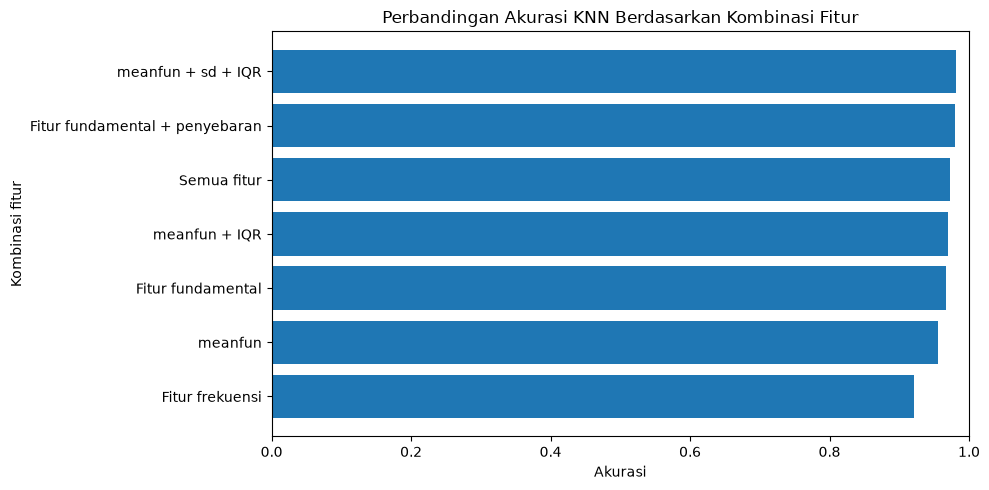

In [7]:
plt.figure(figsize=(10, 5))

plt.barh(
    df_hasil_fitur['Kombinasi fitur'],
    df_hasil_fitur['Akurasi']
)

plt.xlabel('Akurasi')
plt.ylabel('Kombinasi fitur')
plt.title('Perbandingan Akurasi KNN Berdasarkan Kombinasi Fitur')
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [8]:
fitur_terbaik_nama = df_hasil_fitur.iloc[0]['Kombinasi fitur']

fitur_terbaik = kombinasi_fitur[fitur_terbaik_nama]

print("Kombinasi fitur terbaik:", fitur_terbaik_nama)
print("Fitur yang digunakan:", fitur_terbaik)
print("Akurasi:", df_hasil_fitur.iloc[0]['Akurasi'])

Kombinasi fitur terbaik: meanfun + sd + IQR
Fitur yang digunakan: ['meanfun', 'sd', 'IQR']
Akurasi: 0.9810725552050473


In [9]:
hasil_k = []

for k in range(1, 26):
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    model.fit(X_train[fitur_terbaik], y_train)

    prediksi_train = model.predict(X_train[fitur_terbaik])
    prediksi_test = model.predict(X_test[fitur_terbaik])

    hasil_k.append({
        'k': k,
        'Akurasi Train': accuracy_score(y_train, prediksi_train),
        'Akurasi Test': accuracy_score(y_test, prediksi_test)
    })

df_hasil_k = pd.DataFrame(hasil_k)

print(df_hasil_k)

     k  Akurasi Train  Akurasi Test
0    1       1.000000      0.971609
1    2       0.981452      0.970032
2    3       0.980663      0.977918
3    4       0.979874      0.981073
4    5       0.979479      0.981073
5    6       0.978295      0.982650
6    7       0.978295      0.982650
7    8       0.979084      0.981073
8    9       0.979479      0.981073
9   10       0.979479      0.979495
10  11       0.979479      0.979495
11  12       0.978295      0.979495
12  13       0.977901      0.982650
13  14       0.975927      0.981073
14  15       0.975927      0.981073
15  16       0.975138      0.979495
16  17       0.973560      0.979495
17  18       0.973165      0.977918
18  19       0.972770      0.977918
19  20       0.972770      0.977918
20  21       0.972770      0.977918
21  22       0.972770      0.974763
22  23       0.972376      0.973186
23  24       0.972376      0.974763
24  25       0.971981      0.971609


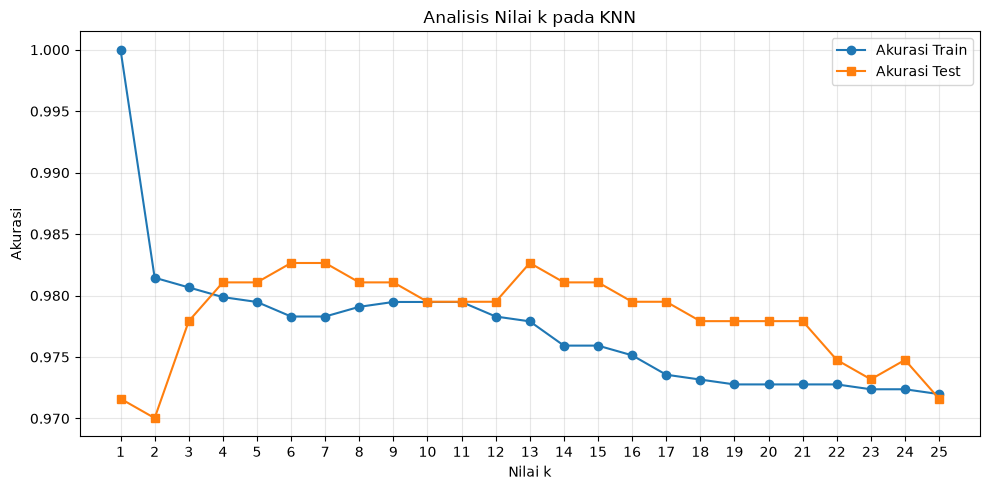

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    df_hasil_k['k'],
    df_hasil_k['Akurasi Train'],
    marker='o',
    label='Akurasi Train'
)

plt.plot(
    df_hasil_k['k'],
    df_hasil_k['Akurasi Test'],
    marker='s',
    label='Akurasi Test'
)

plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.title('Analisis Nilai k pada KNN')
plt.xticks(range(1, 26))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
baris_terbaik = df_hasil_k.loc[
    df_hasil_k['Akurasi Test'].idxmax()
]

print("Nilai k terbaik:", int(baris_terbaik['k']))
print(f"Akurasi train: {baris_terbaik['Akurasi Train']:.4f}")
print(f"Akurasi test: {baris_terbaik['Akurasi Test']:.4f}")

Nilai k terbaik: 6
Akurasi train: 0.9783
Akurasi test: 0.9826
